# UE Data Mining – Projet 2026-2027 : le narratif caché

**Master 2 Intelligence Artificielle / Master 2 Data Science**

* **Nom du groupe :** G05
* **Membres du groupe :**
    * DJOUADI Hanane
    * YENNEK Aldjia
    * LAIB Merieme
    * COLMEK Esra
    * EL OUARRAD Mariam
    * KOUAMÉ Côme


## Sommaire

1. [Objectif, données et organisation](#1)
2. [Démarche méthodologique commune](#2)
3. [Dossier `public_records`](#3)
4. [Dossier `health`](#4)
5. [Dossier `ecology`](#5)
6. [Dossier `logistics`](#6)
7. [Croisement des dossiers : vérifications reproductibles](#7)
8. [Narratif reconstitué](#8)
9. [Limites et regard critique sur la méthode](#9)
10. [Conclusion](#10)
11. [Usage de l'IA générative](#11)
12. [Annexes : où trouver le détail](#12)

**Comment lire ce rapport.** Les sections 3 à 6 résument, dossier par dossier, les choix de méthode et les résultats des notebooks d'analyse (les chiffres viennent de leurs sorties ; les figures sont celles extraites de ces notebooks). La section 7 est le cœur du rapport : chaque lien entre dossiers y est **recalculé dans ce notebook** à partir des fichiers nettoyés, pour que le raisonnement soit vérifiable. La section 8 assemble ces liens en un récit, en distinguant ce qui est observé de ce qui est supposé.

<a id="1"></a>
## 1. Objectif, données et organisation

### 1.1 Objectif

Mettre en évidence le **narratif caché** dans quatre dossiers de données à l'aide des méthodes vues dans l'UE : nettoyage, analyse exploratoire, clustering, règles d'association et détection d'anomalies, graphes et process mining, analyse spatiale et temporelle, fouille de texte.

Le narratif n'est écrit nulle part en entier. Il faut le reconstituer à partir de signaux faibles répartis entre des fichiers qui ne partagent pas de clé commune explicite. Notre question directrice a donc été double :

* **dans chaque fichier** : qu'est-ce qui est atypique, et est-ce une erreur, un artefact de génération, un leurre ou un vrai signal ?
* **entre les fichiers** : quels identifiants, noms, dates et lieux relient ces signaux ?

### 1.2 Les données

| Dossier | Contenu | Fichiers |
|---|---|---|
| `public_records` | Registres administratifs : entités, dirigeants, nominations publiques, licences, journaux de dossiers réglementaires et d'accès aux sites, mémos et documents | 9 |
| `health` | Données cliniques : patients, consultations, observations, procédures, notes, enregistrements cardiaques | 7 |
| `ecology` | Suivi environnemental : relevés de chauves-souris, environnement mensuel, capteurs, rapports de terrain, sites, vergers | 6 |
| `logistics` | ERP d'entreprises : sites, partenaires, commandes, réceptions, expéditions, stocks, ajustements | 7 |

Le fichier `data/data_dictionary.csv` décrit chaque variable. La cellule suivante dresse l'inventaire des fichiers nettoyés utilisés dans ce rapport.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# Ce notebook est à lancer depuis la racine du dépôt
DATA = Path("data")
assert DATA.exists(), "Lancer le notebook depuis la racine du dépôt (dossier qui contient data/)"
PR = DATA / "public_records"
HE = DATA / "health" / "cleaned"
EC = DATA / "ecology" / "cleaned"
LO = DATA / "logistics" / "cleaned"

# Date de référence commune pour les mandats et licences en cours
REF_DATE = pd.Timestamp("2025-12-31")

In [2]:
sources = {
    "public_records": sorted(PR.glob("*_cleaned.csv")),
    "health": sorted(HE.glob("*.csv")),
    "ecology": sorted(EC.glob("*.csv")),
    "logistics": sorted(LO.glob("*.csv")),
}
rows = []
for dossier, files in sources.items():
    for f in files:
        if "encoded" in f.name:          # versions encodées pour le clustering, non comptées
            continue
        df = pd.read_csv(f, low_memory=False)
        nom = f.stem.replace("_cleaned", "").replace("_clean", "")
        rows.append({"dossier": dossier, "fichier": nom, "lignes": len(df), "colonnes": df.shape[1]})
inventaire = pd.DataFrame(rows)
display(inventaire)
print(inventaire.groupby("dossier").agg(fichiers=("fichier", "count"), lignes=("lignes", "sum")))

                fichiers  lignes
dossier                         
ecology                6   16318
health                 7  116350
logistics              7    2459
public_records         9     991


,dossier,fichier,lignes,colonnes
0,public_records,institutional_memos,30,12
1,public_records,licensed_facilities,3,12
2,public_records,licensed_professionals,53,10
3,public_records,officer_filings,135,12
4,public_records,public_and_investigative_documents,40,11
5,public_records,public_appointments,62,12
6,public_records,registered_entities,24,10
7,public_records,regulatory_case_events,232,16
8,public_records,site_access_case_events,412,15
9,health,cardiac_recordings,44,19


### 1.3 Organisation du travail

Chaque dossier a été confié à un ou plusieurs membres, puis les résultats ont été mis en commun et discutés en groupe (réunions et serveur Discord) pour faire les croisements.

| Dossier | Membres | Notebooks d'analyse | Synthèse |
|---|---|---|---|
| `public_records` (6 fichiers : dirigeants, nominations, licences, établissements, mémos, documents) | COLMEK Esra | `nettoyage`, `exploration`, `clustering`, `anomalies` | `data/public_records/synthèses/synthese_public_records.md` |
| `public_records` (3 fichiers : entités, dossiers réglementaires, dossiers d'accès) | KOUAMÉ Côme | `clustering_public_records`, `anomalies_public_records` | idem (synthèse fusionnée) |
| `health` (partie clinique) | EL OUARRAD Mariam | `cleaning`, `eda`, `clustering`, `patterns_anomalies`, `graphs_process`, `spatio_temporal`, `text_mining`, `narrative` | `data/health/syntheses/SYNTHESE_DOSSIER_HEALTH.md` |
| `health` (partie cardiaque) | KOUAMÉ Côme | `clustering_cardiac`, `anomalies_cardiac` | `data/health/syntheses/synthese_cardiac.md` |
| `ecology` | DJOUADI Hanane, YENNEK Aldjia, LAIB Merieme | un notebook par fichier | `data/ecology/syntheses/synthese_ecology.md` |
| `logistics` | DJOUADI Hanane, YENNEK Aldjia, LAIB Merieme | un notebook par fichier + `analyse_logistics` | `data/logistics/syntheses/synthese_logistics.md` |
| Croisement et rapport | tout le groupe | ce notebook | — |

**Règles communes que nous nous sommes fixées :**

* les fichiers bruts ne sont jamais modifiés : chaque dossier a son notebook de nettoyage qui écrit des fichiers `*_cleaned.csv` ;
* une synthèse par dossier suit le même gabarit (choix techniques, anomalies, preuves, croisement) pour pouvoir comparer les dossiers ;
* chaque chiffre cité dans une synthèse doit pouvoir être retrouvé dans une cellule de notebook ;
* les liens supposés entre dossiers sont listés dans chaque synthèse (« à croiser ») puis vérifiés en commun.

<a id="2"></a>
## 2. Démarche méthodologique commune

Nous avons appliqué à chaque fichier le même enchaînement de blocs, en **sautant explicitement** un bloc quand il n'avait pas de sens pour le fichier (et en écrivant pourquoi). Le tableau ci-dessous résume l'enchaînement ; les paragraphes qui suivent justifient les choix qui ont le plus pesé sur les résultats.

| Étape | Méthodes | Quand nous l'avons sautée |
|---|---|---|
| 0. Nettoyage | doublons (exacts et sur la clé), formats de dates mixtes, virgules décimales, unités dans les valeurs, casse et espaces des catégories, manquants traités au cas par cas | jamais |
| 1. Exploration (EDA) | typage, `describe`, histogrammes et boxplots, normalité (Shapiro-Wilk, asymétrie), `value_counts`, tableaux croisés, Pearson et Spearman, dates converties en durées | jamais |
| 2. Clustering | encodage one-hot, standardisation, PCA et t-SNE pour visualiser, K-Means (coude, silhouette), CAH (Ward, ou distance de Hamming pour les variables nominales), DBSCAN (eps lu sur la courbe des k-distances), comparaison des partitions par l'ARI | moins de ~10 lignes, ou une seule variable exploitable |
| 3. Patterns et anomalies | Apriori / FP-Growth (support, confiance, lift, leverage) ; univarié : IQR, z-score, z-score modifié (MAD) ; multivarié : Isolation Forest, LOF ; règles logiques métier | règles d'association : moins de 2–3 variables catégorielles |
| 4. Graphes et process mining | graphes bipartis personnes–organisations, projections, centralités (degré, betweenness), communautés (Louvain) ; process mining sur les journaux d'événements | process mining seulement pour un vrai journal (identifiant de cas + activité + horodatage) |
| 5. Spatial et temporel | jointures avec les référentiels de sites, distances Haversine, Moran / LISA si assez de points, séries mensuelles, ACF, décomposition STL, z-score sur fenêtre glissante | Moran / LISA avec moins d'une dizaine de lieux |
| 6. Texte | dédoublonnage, `nltk`, TF-IDF, n-grams, similarité cosinus, LDA, concordancier | quand il n'y a pas de vrai corpus |
| 7. Croisement | jointures sur identifiants, noms, dates et sites partagés entre dossiers | — |

### 2.1 Nettoyage : ne pas effacer les indices

Les données contiennent des défauts volontaires (formats mixtes, doublons, catégories mal écrites) **et** des valeurs extrêmes qui sont justement les indices. Nous avons donc séparé deux types d'opérations :

* **corriger la forme** : dates converties avec `format="mixed"`, unités retirées du texte, catégories harmonisées (par exemple 18 écritures de `land_use_category` pour 8 catégories réelles), doublons exacts supprimés ;
* **ne jamais corriger le fond** : aucune valeur extrême n'a été supprimée ou plafonnée. Une licence délivrée en 1886 ou un mandat qui finit avant d'avoir commencé est conservé, puis étudié.

Les valeurs manquantes ont été interprétées avant d'être imputées. Par exemple, dans `officer_filings`, les 77 `cessation_date` vides correspondent exactement aux 77 mandats actifs : ce sont des mandats **en cours**, pas des données perdues. De même, `fault_code` vide dans les capteurs signifie « aucune panne ». Imputer ces vides aurait créé de fausses informations.

### 2.2 Exploration : transformer les dates en grandeurs comparables

La plupart des fichiers sont dominés par des dates et des catégories. Les dates brutes ne se comparent pas bien ; nous les avons converties en **durées** (durée d'un mandat, âge à la nomination, délai de déclaration, délai entre deux événements d'un dossier), avec une date de référence commune (31/12/2025) pour ce qui est en cours. Beaucoup d'anomalies ne sont apparues qu'après cette conversion (durées négatives, âges impossibles).

Les distributions sont rarement normales (Shapiro-Wilk rejette presque toujours la normalité, asymétries fortes), ce qui a orienté le choix des détecteurs (2.4) et des corrélations (Spearman en plus de Pearson).

### 2.3 Clustering : un outil de description plus que de découverte

* **Encodage.** Les variables nominales sont encodées en one-hot. Quand toutes les variables sont nominales (licences, procédures), nous avons utilisé la **distance de Hamming** avec une CAH à liaison moyenne, plutôt que K-Means, dont la distance euclidienne n'a pas de sens sur des indicatrices.
* **Choix de k.** Coude et silhouette, mais **la silhouette n'a pas été suivie aveuglément** : dans plusieurs fichiers elle augmente avec k (chaque catégorie forme un petit groupe parfait), elle ne désigne alors pas de k optimal et nous avons retenu un k lisible.
* **Stabilité.** Chaque partition K-Means est comparée à une CAH (ARI). Un ARI faible (0,5 sur les dossiers d'accès) signale un découpage fragile.
* **Lecture.** Pour chaque cluster nous avons cherché la variable qui l'explique. Dans la majorité des fichiers, le clustering **retrouve une variable connue** (nationalité, juridiction, métier, protocole d'acquisition, catégorie de dossier). C'est un résultat en soi : cela montre que la structure « normale » est générée par ces variables et que les vrais signaux sont ailleurs. Les rares clusters qui ne s'expliquent pas ainsi (le cluster Horizon dans les accès, les plaintes de la société civile) sont devenus des pistes.

### 2.4 Anomalies : plusieurs détecteurs, et des règles logiques

Nous n'avons jamais conclu sur un seul détecteur. Pour chaque variable :

* **IQR** (robuste, ne suppose pas de loi) ;
* **z-score** (|z| > 3), sensible à **l'effet de masque** : quand plusieurs valeurs extrêmes gonflent l'écart-type, elles se cachent les unes les autres. Exemple : sur l'année de nomination des dirigeants, le z-score ne voit que 4 des 5 nominations antérieures à 1960 ;
* **z-score modifié** (médiane et MAD, |z| > 3,5), qui corrige ce masque.

En multivarié, **Isolation Forest** (isole les points faciles à séparer, voit bien les groupes atypiques) et **LOF** (densité locale, voit les points isolés dans leur voisinage) sont complémentaires ; une **anomalie concordante** est signalée par plusieurs méthodes. Le paramètre `contamination` fixe la proportion de points signalés : nous l'avons choisi faible (2 à 8 %) et fait varier pour vérifier la stabilité.

Enfin, une partie importante des anomalies **ne peut pas être vue par une méthode statistique** : un mandat de −1 jour n'est pas extrême au sens de l'IQR. Nous avons donc écrit des **règles logiques** (fin avant début, auteur signant hors de son mandat, âge impossible d'un titulaire de licence, personne citée après son décès, borne physique à 0 d'un effectif). Ce sont elles qui ont produit plusieurs des indices les plus forts.

### 2.5 Principe de prudence

Les données sont synthétiques et contiennent des **leurres** (documents qui donnent une explication banale aux termes clés, notes gabarits, dates plafonnées). Nous avons classé chaque élément en trois niveaux, utilisés dans tout le rapport :

| Niveau | Définition | Exemple |
|---|---|---|
| **Observation** | fait vérifiable dans un fichier, recalculable | 30 procédures `MRP-42` réservées, toutes réalisées par la même licence |
| **Lien** | coïncidence d'identifiants, de dates ou de lieux entre fichiers, testée quand c'est possible | chaque accès nocturne d'Horizon est suivi le lendemain d'une expédition d'échantillons biologiques |
| **Hypothèse** | interprétation qui relie plusieurs liens, non démontrée | les chauves-souris collectées serviraient à un traitement ou à une consommation |

Un signal statistique n'est pas une preuve d'intention, et une coïncidence de date n'est pas une causalité.

<a id="3"></a>
## 3. Dossier `public_records`

Neuf fichiers : `registered_entities`, `officer_filings`, `public_appointments`, `licensed_facilities`, `licensed_professionals`, `regulatory_case_events`, `site_access_case_events`, `institutional_memos`, `public_and_investigative_documents`. Synthèse complète : `data/public_records/synthèses/synthese_public_records.md`.

### 3.1 Choix techniques propres au dossier

* **Variables construites.** Durée du mandat, âge à la nomination, délai de déclaration ; `birth_year_or_age_band` séparée en année exacte ou milieu de tranche (`1970–1979` → 1974,5) ; un **niveau hiérarchique** déduit du titre (1 = agent, 2 = cadre, 3 = sommet de l'État).
* **Journaux d'événements agrégés par dossier** (nombre d'événements, durée, valeurs modales de l'agence, de l'objet, du matériel et de la confidentialité), après des contrôles de cohérence qui passent tous (pas d'événement hors ordre, chaînage `previous_status` → `new_status` continu, agence conforme au préfixe du site).
* **Fichiers trop petits ou trop pauvres.** `licensed_facilities` (3 lignes) n'est que décrit ; les documents n'ont que 2 variables nominales, donc pas de clustering : nous avons construit des mesures (longueur, **part de paragraphes gabarits** répétés dans au moins 3 documents, nombre de références `SHP-`, `PO-`, `ADJ-`…).
* **Patterns.** Pour les dirigeants, une transaction = une personne, les items = les entreprises où elle a siégé et sa nationalité.

### 3.2 Résultats

| Fichier | Résultat principal | Méthode qui l'a révélé |
|---|---|---|
| `public_appointments` + `officer_filings` | **8 personnes au sommet depuis 39 à 57 ans** (4 dirigeants politiques, 4 chefs d'entreprise) ; le groupe est stable pour tout seuil de 30 à 38 ans | règle d'ancienneté sur les deux fichiers réunis ; en univarié seule Elira Vaun ressort |
| `officer_filings` | **5 nominations de 1840 à 1952** ; **deux lignées** de noms qui se succèdent sans chevauchement : Vann (1840) → Warden → Vosmere → **Elias Voss** (Meridian, 1996) et Varlan (1885) → Bell → Marot → **Jacob Vale** (2008) | IQR et z-score modifié (le z-score classique en manque une, effet de masque) ; frise chronologique |
| `officer_filings` + `public_appointments` | **9 mandats à durée négative**, dont 3 qui cachent un double poste Asterion ↔ Tembara Coastal Administration (Corda, Quorin, Koral) | règle logique (aucune méthode statistique ne les voit : la borne IQR basse est à −2 786 jours) |
| `officer_filings` | dirigeants partagés entre camps opposés : *Common Ground Climate Forum ⇒ Meridian–Asterion Foundation* (confiance 1, lift 13) ; *Horizon ⇒ Ardena Capital Union* | Apriori |
| `licensed_professionals` | licences de **1886, 1895, 1924 toujours actives** (titulaires de 163, 154 et 125 ans) ; une licence délivrée en **2026** | IQR, croisement avec les années de naissance |
| `registered_entities` | entités dissoutes de **1838, 1883, 1894** = entreprises des lignées ; **Whitehaven** à la même adresse que Meridian | IQR ; contrôle des adresses |
| `regulatory_case_events` | **10 dossiers ouverts par la société civile**, jamais classés sans suite ; 4 visent Meridian, 6 visent l'agence qui autorise Horizon sur le même site | cluster pur (source, catégorie, agence) ; règles à 100 % |
| `site_access_case_events` | **Horizon Field Research Cooperative** : 18 dossiers, accès de nuit 18 h → 03 h, revue de sécurité (12/18, aucune ailleurs), 14/18 confidentiels | IQR sur l'heure (le z-score ne voit rien : heures en paliers) ; Isolation Forest (14 des 18 premiers) ; cluster |
| mémos + documents | **11 documents sur 70 sans aucun texte gabarit** portent le récit (CHAMELEO, Unwabu, *Eonycteris spelaea*, « Chamaeleonidian », transfert « non terrestre ») ; des **leurres** donnent une explication banale de ces termes | z-score modifié sur la part de gabarit (l'IQR échoue : borne négative) |
| mémos | `MEM-510128` signé en 2018 par Adrian Vosmere, dont le mandat a pris fin en 1991 (entreprise dissoute en 1994) | règle logique auteur × mandat |

### 3.3 Figures clés

![Ancienneté au sommet](data/public_records/figures/bloc3_16_1.png)

*Années au poste des personnes au sommet (`anomalies.ipynb`). En rouge, les 8 personnes au-delà de 30 ans ; Elias Voss est à 30.*

![Deux lignées](data/public_records/figures/bloc3_10_1.png)

*Frise des deux lignées de `officer_filings` : les mandats se succèdent sans se chevaucher de 1840 à 2025, avec des initiales qui se répètent.*

![Double poste caché](data/public_records/figures/bloc3_18_1.png)

*Mandats Asterion déclarés terminés la veille de la nomination publique, alors qu'ils commencent après.*

![Part de texte gabarit](data/public_records/figures/bloc3_25_2.png)

*Part de paragraphes gabarits par document : les 11 documents à 0 portent le récit.*

### 3.4 Ce que nous en retenons

Le clustering n'apporte presque rien de caché ici (les clusters sont la nationalité, la juridiction, le métier ou la catégorie). Les indices viennent de **trois sources** : les valeurs extrêmes sur des durées construites, les **règles logiques** sur les dates, et la **structure du texte** (gabarit contre texte unique). Deux acteurs ressortent : le groupe des **8 élites** et **Horizon**.

<a id="4"></a>
## 4. Dossier `health`

Partie clinique (`patient_administration`, `clinical_encounters`, `clinical_observations`, `clinical_procedures`, `clinical_notes`) et partie cardiaque (`cardiac_recordings`, `cardiac_signal_samples`). Synthèses : `data/health/syntheses/SYNTHESE_DOSSIER_HEALTH.md` et `synthese_cardiac.md`.

### 4.1 Choix techniques propres au dossier

* **Nettoyage** : 6 doublons retirés, `numeric_value` convertie, catégories normalisées, aucun aberrant supprimé.
* **EDA par type de mesure** : `numeric_value` mélange des grandeurs différentes (pouls, score cognitif, âge biologique…) ; elle n'a de sens que décrite par `observation_name`.
* **Anomalie bivariée** : l'écart entre la fréquence apicale et le pouls n'est visible qu'en croisant deux mesures prises au même moment.
* **Graphes** : graphe biparti patients – praticiens, puis **sous-graphe restreint** aux procédures réservées ; la structure n'apparaît qu'en contexte restreint.
* **Texte** : dédoublonnage avant TF-IDF (26 notes sont des gabarits et 42 phrases sont dupliquées, ce qui fausse les fréquences), puis lecture en concordancier.
* **Tests d'hypothèses** (bloc narratif) : comparaisons avant / après, Mann-Whitney, Wilcoxon, Fisher, correction de Bonferroni.
* **Cardiaque** : le signal brut n'est pas analysable point par point (IQR et z-score signalent les pics R, c'est-à-dire la forme normale du signal) ; chaque enregistrement est résumé (amplitude, bruit, fréquence estimée, corrélation entre canaux) avant le clustering.

### 4.2 Résultats

| Indice | Observation | Méthode |
|---|---|---|
| **`MRP-42`** | 30 administrations `restricted_specialist` pour 8 patients, environ **tous les 742 jours** depuis 2014, toujours le jeudi ou le vendredi à 09 h 05 ; 20 autres patients la reçoivent une fois (`research_restricted`) | fréquences, chronologie |
| **Un seul médecin** | **LIC-VLN-MED-1002 (Dr. Naima Orrel)** réalise les 30 ; betweenness 0,50 dans le graphe restreint | graphe biparti |
| **Âge biologique** | écart âge biologique − âge réel : −4,6 ans avant, **−12,4 ans après** `MRP-42` (autres patients : −1,0 ; Mann-Whitney p ≈ 1e-12) | test non paramétrique |
| **Seconde source cardiaque** | **35 patients** ont une fréquence apicale ≈ +20 bpm au-dessus du pouls (109 observations « discordant ») ; ils balancent plus et sont moins bien reconnus par les caméras ; aucun lien avec `MRP-42` (Fisher p = 0,78) | anomalie bivariée, tests corrigés |
| **Notes** | 4 notes rédigées sur 30 ; `CLN-510025` relie le patient **PAT-31065** à l'identité publique **Elias Voss** | fouille de texte, concordancier |
| **Cardiaque** | les clusters retrouvent le protocole d'acquisition ; PAT-31065 a deux ECG le même jour (`irregular` puis `review_required`) | K-Means, Isolation Forest |
| **Artefacts écartés** | inscriptions toutes au 1er du mois ; 22 consultations le 20/06/2025 (dates plafonnées) ; leurres `CLN-510126`, `CLN-510039` | lecture du contexte |

![Âge biologique et MRP-42](data/health/syntheses/images/fig1_bioage_mrp42.png)

*Écart entre âge biologique et âge réel avant et après `MRP-42`.*

![Apical contre pouls](data/health/syntheses/images/fig4_apical_vs_pouls.png)

*Les observations discordantes forment un groupe séparé, visible seulement en bivarié.*

### 4.3 Ce que nous en retenons

Deux populations distinctes : les **8 patients de `MRP-42`**, dont l'âge biologique diverge, et les **35 patients à double rythme cardiaque**, dont fait partie le patient relié à Elias Voss. Les tests montrent que ces deux groupes ne se recouvrent pas.

<a id="5"></a>
## 5. Dossier `ecology`

Six fichiers : `bat_surveys`, `environmental_monthly`, `monitoring_device_operations`, `environmental_field_reports`, `monitoring_sites`, `orchard_surveys`. Synthèse : `data/ecology/syntheses/synthese_ecology.md`.

### 5.1 Choix techniques propres au dossier

* **Nettoyage** : équipes d'observation manquantes inférées par site (chaque site a toujours la même équipe, hypothèse vérifiée) ; `weather_exception_code` et `fault_code` vides recodés (`NORMAL`, « aucune panne ») ; virgules décimales et unités corrigées.
* **Z-score contextuel par site** : une même valeur n'a pas le même sens sur deux sites, donc le z-score est calculé site par site.
* **Fenêtre glissante et STL** sur la série de chaque site, pour comparer un mois à son passé récent et à sa saison.
* **Comparaison annuelle** : chaque relevé est comparé au même mois de l'année précédente sur le même site (4 198 comparaisons).
* **Sites** : distances Haversine, IQR / z régionaux, LOF régional, graphe de proximité à plusieurs seuils.

### 5.2 Résultats

| Indice | Observation |
|---|---|
| **KNT-KES, avril 2024** | les colonies tombent de 27,9 à 9,5 (**−65,9 %**, `BAT-0000064`), alors qu'avril est normalement un mois fort (record de 50,0 en avril 2022) |
| **Rapport d'intrusion** | `EFR-510088` (02/04/2024, KNT-KES, classé `restricted`) : matériel de retenue coupé, traces de manipulation récentes, aucun animal mort ; l'auteur et la raison ne sont pas identifiés |
| **KNT-KES, avril 2021** | creux de 10,6 contre 28,5 un an avant (−62,8 %), sans rapport de terrain |
| **Causes alternatives écartées** | environnement de KNT-KES dans sa plage habituelle ; capteur en routine, `NO_FAULT` |
| **Autres fichiers** | sites perturbés (`environmental_monthly`), vraies pannes de capteurs, sites isolés sans erreur de coordonnées, relevés de vergers atypiques ; association vergers ↔ chauves-souris modeste (Spearman ≈ 0,15–0,20) |

### 5.3 Un résultat méthodologique important : l'angle mort du z-score

La baisse d'avril 2024 **n'est signalée par aucune méthode standard** (z contextuel −0,86 ; Isolation Forest et LOF la placent au centre du nuage). La raison est mathématique : sur KNT-KES, μ ≈ 18,57 et σ ≈ 10,52 ; un effectif ne pouvant pas descendre sous 0, le z-score minimal possible vaut (0 − 18,57) / 10,52 = **−1,76**. Une baisse ne peut donc **jamais** franchir le seuil |z| > 2 sur ce site, alors que les hausses le peuvent : les 3 seules anomalies contextuelles de KNT-KES sont des pics de population. Il a fallu changer de mesure (variation par rapport au même mois de l'année précédente) pour voir la baisse.

![Série KNT-KES](data/ecology/figures/bat_surveys_138_1.png)

*Série des colonies à KNT-KES et baisse d'avril 2024.*

![Variations annuelles](data/ecology/figures/bat_surveys_176_1.png)

*Distribution des 4 198 variations annuelles : 8,1 % sont des baisses d'au moins 60 %. Une baisse de cette ampleur n'est donc pas exceptionnelle en soi ; c'est son contexte (avril, intrusion) qui la rend intéressante. La section 7.4 reprend cette comparaison.*

<a id="6"></a>
## 6. Dossier `logistics`

Sept fichiers : `erp_facilities`, `erp_business_partners`, `purchase_order_lines`, `goods_receipts`, `shipments`, `inventory_month_end`, `inventory_adjustments`, plus un notebook de croisement `analyse_logistics`. Synthèse : `data/logistics/syntheses/synthese_logistics.md`.

### 6.1 Choix techniques propres au dossier

* **Incohérences conservées** : la formule de stock (ouverture + flux ≠ clôture) n'est pas corrigée, c'est une information.
* **Quantités comparées par catégorie et par unité** : on ne compare pas des caisses et des lots scellés.
* **Tests de proportions avec correction de Benjamini-Hochberg** pour les pics de réception et les taux d'attente qualité (beaucoup de sites et de mois testés en même temps).
* **Graphes** : réseau orienté des flux (origine → destination), graphe des partenaires signalés, graphe documentaire ajustement ↔ réception / expédition.
* **Contrôle chronologique** des références : un ajustement qui cite une expédition postérieure est signalé.

### 6.2 Résultats

| Indice | Observation |
|---|---|
| **FCL-1010** (Asterion Central Clinical Campus) | hub de stock médical (moyenne 167,6, max 270,6), 65 commandes sur 650, destination de **34,5 %** du volume d'expéditions signalé |
| **BP-30021** (Asterion Clinical Institute) | opère FCL-1010 et est en classe de risque **`review`** ; aucune commande directe BP-30021 × FCL-1010 |
| **Corridor FCL-1011 → FCL-1010** | 334 caisses (19,4 % du volume intercepté), surtout des consommables médicaux, au départ d'un site déclaré `office` sans stockage |
| **Réceptions** | 3 pics de fréquence, tous à FCL-1011 (après correction BH) ; 65 lignes de commande sous-reçues |
| **Ajustements** | 23 quantités atypiques, dont 7 en consommables médicaux ; **21 ajustements citent un document daté après eux** |
| **Partenaires** | les anomalies ERP forment un problème systémique de configuration en Valenne (hub BP-30048), distinct du signal FCL-1010 |

![Réseau des flux](data/logistics/figures/shipments_135_1.png)

*Réseau des flux d'expédition.*

![Série FCL-1010 médical](data/logistics/figures/inventory_month_end_149_1.png)

*Stock médical de FCL-1010.*

### 6.3 Ce que nous en retenons

Le dossier montre **où** le matériel médical se concentre (le campus Asterion) et par quel corridor atypique il arrive. La section 7 montre que FCL-1011 est le siège de Meridian, que ce corridor livre chaque traitement `MRP-42` huit jours avant son administration, et qu'une autre catégorie de flux, passée inaperçue dans l'analyse par fichier, relie la logistique à Horizon et aux grottes.

<a id="7"></a>
## 7. Croisement des dossiers : vérifications reproductibles

Chaque sous-section part d'un indice trouvé dans un dossier et vérifie, à partir des fichiers nettoyés, s'il se retrouve dans un autre. Les cellules sont volontairement courtes et commentées pour que chaque étape du raisonnement puisse être contrôlée.

In [3]:
# Chargement des fichiers utilisés dans les croisements
pa = pd.read_csv(PR / "public_appointments_cleaned.csv", parse_dates=["appointment_start", "appointment_end"])
of = pd.read_csv(PR / "officer_filings_cleaned.csv", parse_dates=["appointment_date", "cessation_date"])
lp = pd.read_csv(PR / "licensed_professionals_cleaned.csv", parse_dates=["license_issue_date"])
ent = pd.read_csv(PR / "registered_entities_cleaned.csv")
acc = pd.read_csv(PR / "site_access_case_events_cleaned.csv", parse_dates=["event_time"])
reg = pd.read_csv(PR / "regulatory_case_events_cleaned.csv", parse_dates=["event_time"])
docs = pd.concat([pd.read_csv(PR / "institutional_memos_cleaned.csv"),
                  pd.read_csv(PR / "public_and_investigative_documents_cleaned.csv")], ignore_index=True)

pat = pd.read_csv(HE / "patient_administration_cleaned.csv")
proc = pd.read_csv(HE / "clinical_procedures_cleaned.csv", parse_dates=["performed_time"])
obs = pd.read_csv(HE / "clinical_observation_cleaned.csv")
notes = pd.read_csv(HE / "clinical_notes_cleaned.csv")

bats = pd.read_csv(EC / "bat_surveys_cleaned.csv", parse_dates=["survey_start"])

fac = pd.read_csv(LO / "erp_facilities_cleaned.csv")
bp = pd.read_csv(LO / "erp_business_partners_cleaned.csv")
ship = pd.read_csv(LO / "shipments_clean.csv", parse_dates=["dispatch_time", "arrival_time"])
adj = pd.read_csv(LO / "inventory_adjustments_cleaned.csv", parse_dates=["adjustment_date"])

# Résidu de nettoyage signalé dans public_records : espaces multiples dans access_purpose
acc["access_purpose"] = acc["access_purpose"].str.replace(r"\s+", " ", regex=True).str.strip()
print("Fichiers chargés.")

Fichiers chargés.


### 7.1 Les 8 élites persistantes et le traitement `MRP-42` (public_records ↔ health)

**Question.** Les personnes qui restent au sommet anormalement longtemps sont-elles les patients du traitement réservé `MRP-42` ?

**Démarche.**
1. Réunir les mandats des deux registres (`public_appointments` pour les postes publics, `officer_filings` pour les dirigeants d'entreprise).
2. Garder les personnes ayant occupé une fonction de **sommet** (chef de gouvernement, gouverneur, ministre principal, président du conseil, président ou directeur général d'une entreprise).
3. Mesurer, pour chaque personne, la durée entre sa première nomination et la fin de son dernier mandat (ou la date de référence s'il est en cours), et garder celles qui dépassent 30 ans.
4. Retrouver ces personnes dans `patient_administration` par leur nom, puis compter leurs procédures `MRP-42` par classe d'autorisation.

In [4]:
A = pa.rename(columns={"office_holder_name": "nom", "office_title": "fonction",
                       "appointment_start": "debut", "appointment_end": "fin"})
B = of.rename(columns={"full_name": "nom", "role_title": "fonction",
                       "appointment_date": "debut", "cessation_date": "fin"})
mandats = pd.concat([A[["nom", "fonction", "debut", "fin"]], B[["nom", "fonction", "debut", "fin"]]])

SOMMET = (r"Head of government|Regional governor|Senior minister|Council president"
          r"|^Executive chair of|^Chief executive of|^Chair of|^Executive director of")
mandats["sommet"] = mandats["fonction"].str.contains(SOMMET)

personnes = mandats.groupby("nom").agg(
    sommet=("sommet", "any"),
    premiere_nomination=("debut", "min"),
    fin=("fin", lambda s: REF_DATE if s.isna().any() else s.max()),   # un mandat ouvert = en cours
)
personnes["annees"] = ((personnes["fin"] - personnes["premiere_nomination"]).dt.days / 365.25).round(1)

# Sensibilité du seuil : combien de personnes au sommet dépassent s années ?
print({s: int(((personnes.sommet) & (personnes.annees > s)).sum()) for s in range(28, 41, 2)})

elites = personnes[personnes.sommet & (personnes.annees > 30)].sort_values("premiere_nomination")
display(elites)

{28: 9, 30: 8, 32: 8, 34: 8, 36: 8, 38: 8, 40: 7}


,sommet,premiere_nomination,fin,annees
nom,,,,
Elira Vaun,True,1965-01-01,2021-09-18,56.7
Oskar Nivren,True,1973-01-01,2025-12-31,53.0
Mirek Talven,True,1974-01-01,2025-12-31,52.0
Celene Varro,True,1977-01-01,2025-12-31,49.0
Leora Kassen,True,1978-01-01,2025-12-31,48.0
Rayan Belen,True,1981-01-01,2025-12-31,45.0
Tavian Serat,True,1984-01-01,2025-12-31,42.0
Adrienne Solva,True,1987-01-01,2025-12-31,39.0


In [5]:
pat["nom"] = (pat["given_name"] + " " + pat["family_name"]).str.title()
mrp = proc[proc["procedure_code"].eq("MRP-42")].merge(pat[["patient_number", "nom"]], on="patient_number")
mrp["groupe"] = np.where(mrp["nom"].isin(elites.index), "8 élites", "autres patients")

display(pd.crosstab(mrp["groupe"], mrp["authorization_class"], margins=True))

reserve = mrp[mrp["authorization_class"].eq("restricted_specialist")].sort_values("performed_time")
print("Licences qui réalisent les MRP-42 réservées :", reserve["performing_license_number"].value_counts().to_dict())
print("Patients des MRP-42 réservées = les 8 élites :", set(reserve["nom"]) == set(elites.index))

suivi = reserve.groupby("nom").agg(
    patient=("patient_number", "first"),
    n_mrp42=("procedure_record_id", "count"),
    premiere=("performed_time", "min"),
    derniere=("performed_time", "max"),
    intervalle_median_j=("performed_time", lambda s: s.diff().dt.days.median()),
)
display(suivi)
print(lp.loc[lp["license_number"].eq("LIC-VLN-MED-1002"), ["license_number", "professional_name", "specialty", "primary_facility_license"]].to_string(index=False))

Licences qui réalisent les MRP-42 réservées : {'LIC-VLN-MED-1002': 30}
Patients des MRP-42 réservées = les 8 élites : True
  license_number professional_name           specialty primary_facility_license
LIC-VLN-MED-1002   Dr. Naima Orrel preventive medicine              FAC-VLN-101


authorization_class,research_restricted,restricted_specialist,All
groupe,,,
8 élites,0,30,30
autres patients,20,0,20
All,20,30,50


,patient,n_mrp42,premiere,derniere,intervalle_median_j
nom,,,,,
Adrienne Solva,PAT-31183,3,2016-06-16 09:05:00,2020-07-02 09:05:00,738.5
Celene Varro,PAT-31119,4,2018-01-26 09:05:00,2024-02-09 09:05:00,742.0
Elira Vaun,PAT-31099,3,2014-07-18 09:05:00,2018-08-10 09:05:00,742.0
Leora Kassen,PAT-31221,5,2016-02-18 09:05:00,2024-03-01 09:05:00,738.5
Mirek Talven,PAT-31174,4,2015-09-10 09:05:00,2021-10-14 09:05:00,742.0
Oskar Nivren,PAT-31074,4,2017-11-03 09:05:00,2025-01-31 09:05:00,875.0
Rayan Belen,PAT-31142,3,2019-03-14 09:05:00,2023-04-06 09:05:00,742.0
Tavian Serat,PAT-31044,4,2017-05-12 09:05:00,2024-08-23 09:05:00,749.0


**Résultat.**

* Le groupe des 8 ne dépend pas du seuil choisi : il reste identique de 30 à 38 ans (Elias Voss est exactement à 30 ans).
* Les **30 `MRP-42` `restricted_specialist` vont toutes à ces 8 personnes, et à personne d'autre** ; les 20 `research_restricted` vont à 20 autres patients. La correspondance est exacte (tableau croisé sans aucune case mixte).
* Elles sont toutes réalisées par **LIC-VLN-MED-1002 (Dr. Naima Orrel)**, avec un intervalle médian de **~742 jours**.
* La dernière administration d'Elira Vaun date d'août 2018 ; la suivante était attendue vers 2020 ; elle décède en septembre 2021.
* Le document `PUB-510045` (Orison Medical Audit Board, 2022) décrit « huit individus » qui reçoivent des interventions récurrentes chez les mêmes cliniciens, avec un âge biologique divergent.

**Niveau : observation** (correspondance exacte, recalculée). Le rôle du traitement dans la longévité reste une **hypothèse**, appuyée par l'âge biologique (section 4) et par le cas de Vaun.

### 7.2 Le comportement d'accès d'Horizon (public_records)

**Question.** Horizon Field Research Cooperative se distingue-t-elle vraiment des autres demandeurs d'accès, et sur quoi ?

**Démarche.** Agréger les événements par dossier, puis comparer Horizon aux autres organisations sur l'heure des événements d'accès (`access_started`, `access_completed`), la durée du dossier, la présence d'une revue de sécurité et la confidentialité.

In [6]:
acc["activite"] = acc["activity"].str.lower().str.strip()
acc["horizon"] = acc["requesting_organization_name"].eq("Horizon Field Research Cooperative")

dossiers = acc.groupby("access_case_number").agg(
    horizon=("horizon", "first"),
    site=("site_code", "first"),
    debut=("event_time", "min"),
    fin=("event_time", "max"),
    revue_securite=("activite", lambda s: (s == "security_review").any()),
    confidentiel=("confidentiality_class", lambda s: s.isin(["confidential", "restricted"]).any()),
    refuse=("activite", lambda s: (s == "authorization_denied").any()),
)
dossiers["duree_j"] = (dossiers["fin"] - dossiers["debut"]).dt.days

heures = (acc[acc["activite"].isin(["access_started", "access_completed"])]
          .assign(h=lambda d: d["event_time"].dt.hour)
          .pivot_table(index="horizon", columns="activite", values="h", aggfunc=lambda s: sorted(set(s))))

profil = dossiers.groupby("horizon").agg(
    dossiers=("site", "size"),
    duree_mediane_j=("duree_j", "median"),
    part_revue_securite=("revue_securite", "mean"),
    part_confidentiel=("confidentiel", "mean"),
    refus=("refuse", "sum"),
).round(2)
display(profil.join(heures).rename(index={True: "Horizon", False: "autres organisations"}))

,dossiers,duree_mediane_j,part_revue_securite,part_confidentiel,refus,access_completed,access_started
horizon,,,,,,,
autres organisations,42,17.0,0.00,0.26,6,[11],[17]
Horizon,18,34.0,0.67,0.78,3,[3],[18]


**Résultat.** Horizon a 18 dossiers, tous de 34 jours ; ses accès commencent à 18 h et finissent à 03 h le lendemain, alors que ceux des autres organisations commencent à 17 h et finissent à 11 h. Elle seule passe par une revue de sécurité. Ses 3 « refus » (ACC-2021-0010, ACC-2023-0013, ACC-2024-0015) sont des renvois pour conditions supplémentaires, suivis deux jours plus tard d'une nouvelle demande accordée : **tous les dossiers d'Horizon aboutissent à un accès**, alors que les 6 refus des autres organisations sont définitifs. **Niveau : observation.**

Cette régularité (toujours la même plage nocturne, 2 à 3 dossiers par an sur 8 sites en rotation) suggère un **programme**, pas une erreur de saisie. La question suivante est donc : que se passe-t-il **après** chaque nuit d'accès ?

### 7.3 Chaque nuit d'accès d'Horizon est suivie d'une expédition d'échantillons biologiques (public_records ↔ logistics)

**Question.** Les accès d'Horizon laissent-ils une trace dans la logistique ?

**Démarche.**
1. Retrouver Horizon dans le référentiel des partenaires ERP (`erp_business_partners`), grâce à son numéro d'enregistrement `REG-AVL-01013`.
2. Lister les expéditions dont Horizon est l'expéditeur.
3. Pour chaque dossier d'accès, prendre la fin de la nuit d'accès (événement de 03 h) et chercher l'expédition d'Horizon partie **le même jour**.
4. Identifier le destinataire et les sites d'arrivée avec `erp_facilities`.

In [7]:
bp_idx = bp.set_index("partner_code")
code_horizon = bp.loc[bp["external_registration_number"].eq("REG-AVL-01013"), "partner_code"].iloc[0]
print("Horizon dans l'ERP :", code_horizon, "-", bp_idx.loc[code_horizon, "partner_name"])

ship["declared_purpose"] = ship["declared_purpose"].str.replace(r"\s+", " ", regex=True).str.strip()
exp_h_tout = ship[ship["sender_partner_code"].eq(code_horizon)]
print(f"Expéditions envoyées par Horizon : {len(exp_h_tout)} sur {len(ship)}")

# Le type d'envoi qui ne ressemble à aucun autre : lots scellés d'échantillons biologiques « de référence »
REF_BIO = "environmental and wildlife reference materials"
print("Expéditions déclarées « %s » : %d, expéditeurs : %s" % (
    REF_BIO, ship["declared_purpose"].eq(REF_BIO).sum(),
    ship.loc[ship["declared_purpose"].eq(REF_BIO), "sender_partner_code"].unique()))
exp_h = exp_h_tout[exp_h_tout["declared_purpose"].eq(REF_BIO)].copy()
print(exp_h[["item_category", "temperature_control_class", "declared_unit"]].value_counts().to_string())

# Fin de chaque nuit d'accès d'Horizon (événement de 03 h)
nuits = (acc[acc["horizon"] & acc["event_time"].dt.hour.eq(3)]
         .groupby("access_case_number").agg(site=("site_code", "first"), fin_nuit=("event_time", "max")))
nuits["jour"] = nuits["fin_nuit"].dt.normalize()
exp_h["jour"] = exp_h["dispatch_time"].dt.normalize()

appariement = nuits.reset_index().merge(exp_h, on="jour", how="left")
nom_site = fac.set_index("facility_code")["facility_name"]
appariement["depart"] = appariement["origin_facility_code"].map(nom_site)
appariement["arrivee"] = appariement["destination_facility_code"].map(nom_site)
appariement["destinataire"] = appariement["receiver_partner_code"].map(bp_idx["partner_name"])
appariement["transporteur"] = appariement["carrier_partner_code"].map(bp_idx["partner_name"])
appariement["delai_h"] = (appariement["dispatch_time"] - appariement["fin_nuit"]).dt.total_seconds() / 3600

display(appariement[["access_case_number", "site", "fin_nuit", "shipment_number", "delai_h",
                     "declared_quantity", "arrivee", "destinataire", "transporteur", "authorization_class"]])
print(f"Nuits d'accès suivies d'une expédition d'Horizon le même jour : "
      f"{appariement['shipment_number'].notna().sum()} / {len(nuits)}")
print(f"Lots « de référence » d'Horizon qui ne suivent pas une nuit d'accès : {len(set(exp_h.shipment_number) - set(appariement.shipment_number))}")

Horizon dans l'ERP : BP-30056 - Horizon Field Research Cooperative
Expéditions envoyées par Horizon : 35 sur 450
Expéditions déclarées « environmental and wildlife reference materials » : 18, expéditeurs : <StringArray>
['BP-30056']
Length: 1, dtype: str
item_category      temperature_control_class  declared_unit
biological_sample  2-8c                       sealed_lot       18
Nuits d'accès suivies d'une expédition d'Horizon le même jour : 18 / 18
Lots « de référence » d'Horizon qui ne suivent pas une nuit d'accès : 0


,access_case_number,site,fin_nuit,shipment_number,delai_h,declared_quantity,arrivee,destinataire,transporteur,authorization_class
0,ACC-2018-0001,TMB-NAC,2018-02-16 03:00:00,SHP-2018-00004,6.0,3,Meridian Tembara Coastal Hub,Meridian BioLogistics,Northstar Cold Chain Services,restricted
1,ACC-2018-0002,KNT-KES,2018-03-23 03:00:00,SHP-2018-00007,6.0,5,Meridian Kintara Biological Aggregation Facility,Meridian BioLogistics,Northstar Cold Chain Services,expedited
2,ACC-2018-0003,AVL-MAR,2018-05-25 03:00:00,SHP-2018-00032,6.0,3,Meridian Avelora Transfer Annex,Meridian BioLogistics,Northstar Cold Chain Services,restricted
3,ACC-2019-0004,TMB-PEL,2019-08-09 03:00:00,SHP-2019-00009,6.0,2,Meridian Tembara Coastal Hub,Meridian BioLogistics,Northstar Cold Chain Services,expedited
4,ACC-2019-0005,KNT-LUM,2019-09-13 03:00:00,SHP-2019-00026,6.0,4,Meridian Kintara Biological Aggregation Facility,Meridian BioLogistics,Northstar Cold Chain Services,expedited
5,ACC-2019-0006,AVL-VEL,2019-11-08 03:00:00,SHP-2019-00041,6.0,7,Meridian Avelora Transfer Annex,Meridian BioLogistics,Northstar Cold Chain Services,restricted
6,ACC-2020-0007,KNT-SEN,2020-04-10 03:00:00,SHP-2020-00019,6.0,2,Meridian Kintara Biological Aggregation Facility,Meridian BioLogistics,Northstar Cold Chain Services,ordinary
7,ACC-2020-0008,AVL-ORR,2020-06-12 03:00:00,SHP-2020-00038,6.0,5,Meridian Avelora Transfer Annex,Meridian BioLogistics,Northstar Cold Chain Services,ordinary
8,ACC-2021-0009,KNT-KES,2021-03-26 03:00:00,SHP-2021-00007,6.0,8,Meridian Kintara Biological Aggregation Facility,Meridian BioLogistics,Northstar Cold Chain Services,expedited
9,ACC-2021-0010,AVL-MAR,2021-05-21 03:00:00,SHP-2021-00028,6.0,2,Meridian Avelora Transfer Annex,Meridian BioLogistics,Northstar Cold Chain Services,ordinary


In [8]:
# Propriétaire de chaque site d'arrivée, rattaché au registre public des entités
sites_arrivee = (fac[fac["facility_code"].isin(appariement["destination_facility_code"])]
                 .merge(bp[["partner_code", "partner_name", "external_registration_number"]],
                        left_on="operating_partner_code", right_on="partner_code"))
display(sites_arrivee[["facility_code", "facility_name", "facility_category", "region",
                       "partner_name", "external_registration_number"]])

# La région du site visité détermine le site Meridian d'arrivée
print(pd.crosstab(appariement["site"].str[:3], appariement["destination_facility_code"]))

destination_facility_code  FCL-1019  FCL-1020  FCL-1024
site                                                   
AVL                               7         0         0
KNT                               0         0         7
TMB                               0         4         0


,facility_code,facility_name,facility_category,region,partner_name,external_registration_number
0,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,Kintara Karst Cluster,Meridian BioLogistics,REG-VLN-01001
1,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,Eastern Avelora Agricultural Cluster,Meridian BioLogistics,REG-VLN-01001
2,FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,Tembara Coastal Cluster,Meridian BioLogistics,REG-VLN-01001


**Résultat.**

* Horizon (`BP-30056`) envoie 35 expéditions. 17 sont des envois ordinaires et variés. Les 18 autres sont des **lots scellés d'échantillons biologiques à 2–8 °C** déclarés « environmental and wildlife reference materials », un type d'envoi qui n'existe que 18 fois dans tout le fichier, **toujours expédié par Horizon**.
* **Chacune des 18 nuits d'accès est suivie d'un de ces lots, parti à 09 h le matin même, 6 heures après la fin de l'accès**, et aucun de ces lots n'est envoyé un autre jour. L'appariement est donc **bijectif**.
* Toutes sont livrées à **Meridian BioLogistics** par Northstar Cold Chain Services, sur un site Meridian qui dépend de la région visitée : Kintara → *Meridian Kintara Biological Aggregation Facility* (FCL-1024), Avelora → *Meridian Avelora Transfer Annex* (FCL-1019), Tembara → *Meridian Tembara Coastal Hub* (FCL-1020).
* Cette correspondance n'avait été vue par aucune analyse fichier par fichier : dans `shipments`, ces 18 lignes sont de petites quantités (2 à 8 lots) qui ne sortent pas comme extrêmes. Elle n'apparaît qu'en **joignant les dates** de deux dossiers différents.

**Niveau : lien fort** (bijection exacte sur 18 cas, même délai à chaque fois).

### 7.4 Les lots disparaissent de l'inventaire (logistics ↔ documents)

**Question.** Que deviennent ces lots une fois arrivés chez Meridian ? Le lanceur d'alerte (`PUB-510079`, Mara Venn) écrit que les *Eonycteris spelaea* « arrivent sous des descriptions d'échantillons biologiques, sont regroupés en unités scellées, puis disparaissent de la séquence normale d'inventaire ».

**Démarche.** Chercher dans `inventory_adjustments` les ajustements qui citent une des 18 expéditions d'Horizon, et regarder leur signe, leur motif et leur date.

In [9]:
adj_h = adj[adj["related_shipment_number"].isin(exp_h["shipment_number"])]
adj_h = adj_h.merge(exp_h[["shipment_number", "dispatch_time", "declared_quantity", "destination_facility_code"]],
                    left_on="related_shipment_number", right_on="shipment_number")
adj_h["jours_apres_envoi"] = (adj_h["adjustment_date"] - adj_h["dispatch_time"].dt.normalize()).dt.days
adj_h["meme_site"] = adj_h["facility_code"].eq(adj_h["destination_facility_code"])

display(adj_h[["related_shipment_number", "facility_code", "meme_site", "adjustment_date", "jours_apres_envoi",
               "declared_quantity", "adjustment_quantity", "unit", "adjustment_reason"]].sort_values("adjustment_date"))
print(f"Expéditions d'Horizon suivies d'un ajustement : {adj_h['related_shipment_number'].nunique()} / {len(exp_h)}")
print(f"Ajustements négatifs : {(adj_h['adjustment_quantity'] < 0).sum()} / {len(adj_h)}")
adj_h["part_retiree"] = -adj_h["adjustment_quantity"] / adj_h["declared_quantity"]
print(f"Lots déclarés : {exp_h['declared_quantity'].sum()} ; lots retirés par ajustement : {-adj_h['adjustment_quantity'].sum():.1f} "
      f"(part retirée par expédition : de {adj_h['part_retiree'].min():.0%} à {adj_h['part_retiree'].max():.0%}, médiane {adj_h['part_retiree'].median():.0%})")

# Point de comparaison : les ajustements des autres lots scellés
autres = adj[adj["unit"].eq("sealed_lot") & ~adj["related_shipment_number"].isin(exp_h["shipment_number"])]
print(f"Autres ajustements de lots scellés : {len(autres)}, dont {(autres['adjustment_quantity'] < 0).sum()} négatifs")

Expéditions d'Horizon suivies d'un ajustement : 18 / 18
Ajustements négatifs : 18 / 18
Lots déclarés : 82 ; lots retirés par ajustement : 52.2 (part retirée par expédition : de 16% à 192%, médiane 68%)
Autres ajustements de lots scellés : 18, dont 8 négatifs


,related_shipment_number,facility_code,meme_site,adjustment_date,jours_apres_envoi,declared_quantity,adjustment_quantity,unit,adjustment_reason
0,SHP-2018-00004,FCL-1020,True,2018-02-28,12,3,-2.01,sealed_lot,cycle count reconciliation
1,SHP-2018-00007,FCL-1024,True,2018-03-31,8,5,-4.14,sealed_lot,transfer posting correction
2,SHP-2018-00032,FCL-1019,True,2018-05-31,6,3,-2.95,sealed_lot,transfer posting correction
3,SHP-2019-00009,FCL-1020,True,2019-08-31,22,2,-2.69,sealed_lot,transfer posting correction
4,SHP-2019-00026,FCL-1024,True,2019-09-30,17,4,-1.08,sealed_lot,quality-hold release
5,SHP-2019-00041,FCL-1019,True,2019-11-30,22,7,-4.81,sealed_lot,transfer posting correction
6,SHP-2020-00019,FCL-1024,True,2020-04-30,20,2,-3.84,sealed_lot,cycle count reconciliation
7,SHP-2020-00038,FCL-1019,True,2020-06-30,18,5,-3.59,sealed_lot,cycle count reconciliation
8,SHP-2021-00007,FCL-1024,True,2021-03-31,5,8,-3.39,sealed_lot,cycle count reconciliation
9,SHP-2021-00028,FCL-1019,True,2021-05-31,10,2,-1.25,sealed_lot,quality-hold release


**Résultat.**

* **Chacune des 18 expéditions d'Horizon est suivie d'un ajustement d'inventaire négatif** sur le site Meridian qui l'a reçue, enregistré en fin de mois (motifs administratifs : « transfer posting correction », « cycle count reconciliation », « quality-hold release »).
* Chaque ajustement retire une part importante du lot reçu (68 % en médiane) : la marchandise **sort du stock sans expédition sortante correspondante**. Le site d'agrégation de Kintara (FCL-1024), qui reçoit les lots des grottes, n'expédie ensuite aucun échantillon biologique.
* Les autres ajustements de lots scellés sont de signes mélangés : la régularité ne vient que des lots d'Horizon.
* Le mémo `MEM-510062` (Meridian, avril 2024) décrit un « déséquilibre d'unités biologiques » sous autorisation restreinte, et `MEM-510100` impose que les envois marqués **CHAMELEO** ne soient enregistrés dans l'inventaire standard que sous leur catégorie déclarée.

**Niveau : lien fort** (18/18), qui **corrobore** le témoignage de `PUB-510079`. La destination finale des lots n'est pas dans les données : `PUB-510063` évoque une destination qui ne correspond à aucun registre terrestre.

### 7.5 Les colonies baissent après chaque visite d'Horizon (public_records ↔ ecology)

**Question.** La baisse de KNT-KES en avril 2024 est-elle un cas isolé, ou les colonies baissent-elles après **chaque** visite d'Horizon ?

**Démarche.**
1. Calculer, pour chaque site et chaque mois, la colonie moyenne estimée (`bat_surveys`).
2. Pour chaque nuit d'accès d'Horizon, prendre le premier relevé du site qui suit la visite, et le comparer au relevé du même mois l'année précédente (variation annuelle, la mesure qui contourne l'angle mort du z-score décrit en 5.3).
3. Comparer ces variations à la distribution de **toutes** les variations annuelles du fichier (référence : 8 % de baisses d'au moins 60 %, médiane proche de 0).
4. Tester : test des signes (les variations après visite sont-elles plus souvent négatives qu'au hasard ?) et test binomial (y a-t-il plus de baisses d'au moins 60 % qu'attendu ?).

In [10]:
bats["mois"] = bats["survey_start"].dt.to_period("M")
serie = bats.groupby(["site_code", "mois"])["colony_estimate"].mean()

# Référence : toutes les variations annuelles (même site, même mois, année précédente)
ref = []
for site, s in serie.groupby(level=0):
    s = s.droplevel(0)
    s.index = s.index.to_timestamp()
    s = s.asfreq("MS")
    ref.append((s / s.shift(12) - 1) * 100)
ref = pd.concat(ref).dropna()
p_baisse60 = (ref <= -60).mean()
print(f"Référence : {len(ref)} variations annuelles, médiane {ref.median():.1f} %, baisses <= -60 % : {p_baisse60:.1%}")

lignes = []
for dossier, r in nuits.iterrows():
    apres = bats[(bats["site_code"] == r["site"]) & (bats["survey_start"] > r["fin_nuit"])
                 & (bats["survey_start"] <= r["fin_nuit"] + pd.Timedelta(days=60))].sort_values("survey_start")
    if apres.empty:
        continue
    m = apres.iloc[0]["mois"]
    n, n1 = serie.get((r["site"], m), np.nan), serie.get((r["site"], m - 12), np.nan)
    lignes.append({"dossier": dossier, "site": r["site"], "fin_nuit": r["fin_nuit"].date(), "mois_releve": str(m),
                   "colonie_n-1": n1, "colonie_n": n, "variation_%": round((n / n1 - 1) * 100, 1) if n1 == n1 else np.nan})
visites = pd.DataFrame(lignes)
display(visites)

v = visites["variation_%"].dropna()
print(f"Visites comparables (relevés disponibles l'année précédente) : {len(v)} / {len(nuits)}")
print(f"Variation médiane après une visite : {v.median():.1f} %")
print(f"Variations négatives : {(v < 0).sum()} / {len(v)}  -> test des signes p = {stats.binomtest((v < 0).sum(), len(v), 0.5, alternative='greater').pvalue:.1e}")
k = (v <= -60).sum()
print(f"Baisses <= -60 % : {k} / {len(v)} (attendu {p_baisse60 * len(v):.1f})  -> test binomial p = "
      f"{stats.binomtest(k, len(v), p_baisse60, alternative='greater').pvalue:.1e}")

Référence : 4224 variations annuelles, médiane 0.0 %, baisses <= -60 % : 8.0%
Visites comparables (relevés disponibles l'année précédente) : 11 / 18
Variation médiane après une visite : -65.9 %
Variations négatives : 11 / 11  -> test des signes p = 4.9e-04
Baisses <= -60 % : 7 / 11 (attendu 0.9)  -> test binomial p = 5.3e-06


,dossier,site,fin_nuit,mois_releve,colonie_n-1,colonie_n,variation_%
0,ACC-2019-0004,TMB-PEL,2019-08-09,2019-09,NaN,7.8,NaN
1,ACC-2019-0005,KNT-LUM,2019-09-13,2019-10,NaN,4.8,NaN
2,ACC-2019-0006,AVL-VEL,2019-11-08,2019-12,NaN,3.1,NaN
3,ACC-2020-0007,KNT-SEN,2020-04-10,2020-05,29.6,12.4,-58.1
4,ACC-2020-0008,AVL-ORR,2020-06-12,2020-07,25.4,7.2,-71.7
5,ACC-2021-0009,KNT-KES,2021-03-26,2021-04,28.5,10.6,-62.8
6,ACC-2021-0010,AVL-MAR,2021-05-21,2021-06,17.0,0.1,-99.4
7,ACC-2022-0011,TMB-NAC,2022-02-18,2022-03,25.8,1.6,-93.8
8,ACC-2023-0012,KNT-LUM,2023-09-15,2023-10,11.2,2.1,-81.2
9,ACC-2023-0013,AVL-VEL,2023-11-10,2023-12,16.1,10.6,-34.2


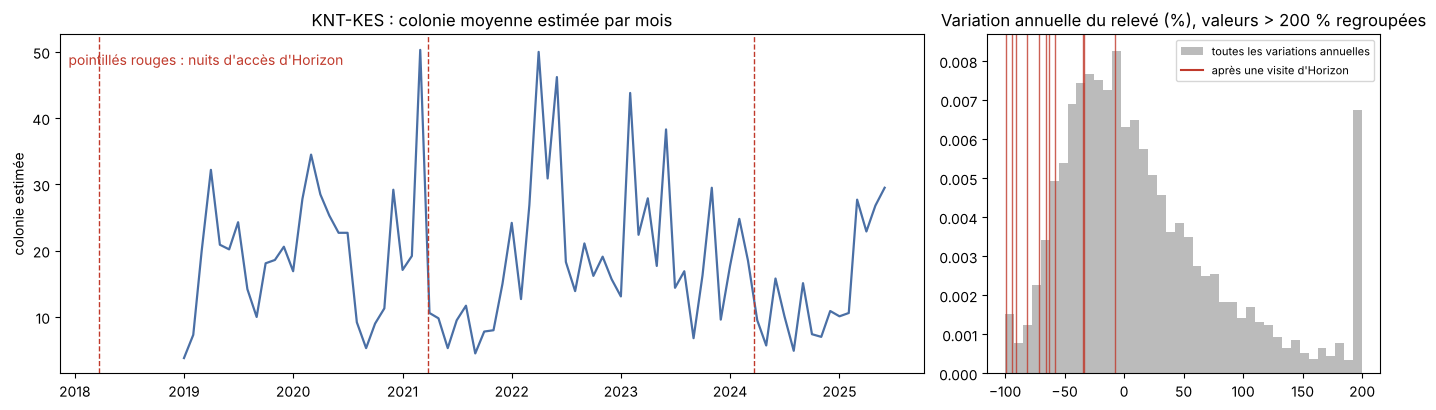

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})

kes = serie.loc["KNT-KES"]
kes.index = kes.index.to_timestamp()
axes[0].plot(kes.index, kes.values, color="#4a6fa5", lw=1.6)
for t in nuits.loc[nuits["site"].eq("KNT-KES"), "fin_nuit"]:
    axes[0].axvline(t, color="#c0392b", ls="--", lw=1)
axes[0].text(0.01, 0.95, "pointillés rouges : nuits d'accès d'Horizon", transform=axes[0].transAxes,
             color="#c0392b", va="top")
axes[0].set_title("KNT-KES : colonie moyenne estimée par mois")
axes[0].set_ylabel("colonie estimée")

axes[1].hist(ref.clip(-100, 200), bins=40, color="#bbbbbb", density=True, label="toutes les variations annuelles")
for x in v:
    axes[1].axvline(x, color="#c0392b", lw=1, alpha=0.8)
axes[1].plot([], [], color="#c0392b", label="après une visite d'Horizon")
axes[1].set_title("Variation annuelle du relevé (%), valeurs > 200 % regroupées")
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()

**Résultat.**

* Les relevés de chauves-souris commencent en janvier 2019 : les visites de 2018 n'ont pas de relevé dans les 60 jours, celles de 2019 n'ont pas d'année précédente, et celle de juin 2025 tombe après la fin des relevés. Il reste **11 visites comparables**.
* **Les 11 relevés qui suivent une visite d'Horizon sont tous en baisse** par rapport à l'année précédente, avec une variation médiane de **−65,9 %**, alors que la médiane de référence est de 0 %. **7 sur 11** sont des baisses d'au moins 60 %, contre moins d'une attendue (8 % de la référence). Le test des signes (p ≈ 5e-4) et le test binomial (p ≈ 5e-6) rejettent nettement le hasard.
* La baisse de KNT-KES en avril 2024 n'est donc **pas un cas isolé** : c'est un cas parmi d'autres d'un même schéma, sur des sites et des années différents (KNT-SEN, AVL-MAR, KNT-LUM, AVL-VEL, TMB-PEL…). Le creux d'avril 2021 à KNT-KES, resté sans explication dans le dossier `ecology`, suit lui aussi une visite (25–26 mars 2021).
* L'intrusion `EFR-510088` (02/04/2024) a lieu onze jours après la visite d'Horizon du 21–22 mars 2024 ; elle décrit du matériel coupé et des traces de manipulation.

**Niveau : lien fort, testé statistiquement.** Les tests supposent les variations indépendantes et 12 cas restent un petit échantillon ; la relation de cause (Horizon prélève les chauves-souris) est une **hypothèse**, mais elle est cohérente avec 7.3, 7.4 et `PUB-510079`.

### 7.6 Le corridor Meridian → Asterion livre chaque `MRP-42` huit jours avant (logistics ↔ public_records ↔ health)

**Question.** Qui se cache derrière les codes FCL-1011 et FCL-1010 du corridor atypique, et que transporte-t-il ?

**Démarche.**
1. Rattacher les sites ERP à leur opérateur, puis l'opérateur au registre public des entités (`external_registration_number` = `registration_number`).
2. Décrire le contenu du corridor.
3. Faire correspondre les établissements de santé et les sites logistiques d'Asterion (FAC-VLN-101 ↔ FCL-1010 campus central, FAC-AVL-201 ↔ FCL-1007 clinique d'Avelora : mêmes noms et mêmes coordonnées), puis chercher, pour chaque `MRP-42`, une livraison reçue par le même établissement dans les 30 jours précédents.

In [12]:
cles = ["FCL-1011", "FCL-1010", "FCL-1007", "FCL-1024", "FCL-1019", "FCL-1020"]
referentiel = (fac[fac["facility_code"].isin(cles)]
               .merge(bp[["partner_code", "partner_name", "risk_class", "external_registration_number"]],
                      left_on="operating_partner_code", right_on="partner_code"))
display(referentiel[["facility_code", "facility_name", "facility_category", "storage_capabilities",
                     "partner_code", "partner_name", "risk_class", "external_registration_number"]])

corridor = ship[ship["origin_facility_code"].eq("FCL-1011") & ship["destination_facility_code"].isin(["FCL-1010", "FCL-1007"])]
print(f"Expéditions du siège de Meridian vers les deux sites d'Asterion : {len(corridor)}")
display(corridor.groupby(["destination_facility_code", "declared_purpose", "item_category"])
        ["declared_quantity"].agg(["count", "sum"]))

Expéditions du siège de Meridian vers les deux sites d'Asterion : 63


,facility_code,facility_name,facility_category,storage_capabilities,partner_code,partner_name,risk_class,external_registration_number
0,FCL-1011,Meridian Valenne Headquarters,office,ambient,BP-30078,Meridian BioLogistics,standard,REG-VLN-01001
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,2-8C;ambient;frozen;secure_cage,BP-30078,Meridian BioLogistics,standard,REG-VLN-01001
2,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,2-8C;ambient;frozen;secure_cage,BP-30078,Meridian BioLogistics,standard,REG-VLN-01001
3,FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,2-8C;ambient;frozen;secure_cage,BP-30078,Meridian BioLogistics,standard,REG-VLN-01001
4,FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,2-8C;controlled_access,BP-30021,Asterion Clinical Institute,review,REG-VLN-01002
5,FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,2-8C;controlled_access,BP-30021,Asterion Clinical Institute,review,REG-VLN-01002


count  sum
destination_facility_code declared_purpose                                   item_category                     
FCL-1007                  agricultural distribution                          agricultural_product        3   58
                                                                             consulting_service          1    1
                                                                             medical_equipment           1   21
                                                                             protective_equipment        1   29
                          customer distribution                              agricultural_product        1   50
                                                                             cold_storage_equipment      1    6
                                                                             medical_consumables         1   82
                                                                             medical_equipment           1    3
                                                                             refrigeration_service       1    1
                          facility replenishment                             agricultural_product        1   15
                                                                             cold_storage_equipment      1    2
                                                                             consulting_service          1    1
                                                                             legal_service               1    1
                          field programme support                            cold_storage_equipment      1   14
                                                                             laboratory_material         1   23
                          laboratory delivery                                agricultural_product        1   26
                                                                             cold_storage_equipment      1    9
                                                                             laboratory_material         2   14
                                                                             medical_consumables         3  103
                          scheduled stock transfer                           agricultural_product        2   44
                                                                             biological_sample           1   18
                                                                             medical_consumables         1   54
                                                                             monitoring_equipment        2   34
                                                                             refrigeration_service       2    2
                          temperature-controlled clinical programme delivery biological_sample           7   35
                                                                             medical_consumables         5  206
FCL-1010                  agricultural distribution                          biological_sample           1    9
                          customer distribution                              agricultural_equipment      1   13
                                                                             office_supply               1   59
                          scheduled stock transfer                           biological_sample           1    7
                                                                             other                       1    8
                          temperature-controlled clinical programme delivery biological_sample           5   29
                                                                             medical_consumables         9  475

In [13]:
CLINIQUE = "temperature-controlled clinical programme delivery"
livraisons = ship[ship["declared_purpose"].eq(CLINIQUE)].copy()
print(f"Livraisons « {CLINIQUE} » : {len(livraisons)} ; expéditeurs : {livraisons['sender_partner_code'].map(bp_idx['partner_name']).unique()}")

FAC_TO_FCL = {"FAC-VLN-101": "FCL-1010", "FAC-AVL-201": "FCL-1007"}
mrp["site_logistique"] = mrp["performing_facility_license"].map(FAC_TO_FCL)

def livraison_precedente(r, fenetre=30):
    c = livraisons[livraisons["destination_facility_code"].eq(r["site_logistique"])]
    d = (r["performed_time"].normalize() - c["dispatch_time"].dt.normalize()).dt.days
    c = c[(d >= 0) & (d <= fenetre)]
    if c.empty:
        return pd.Series({"livraison": None, "delai_j": np.nan, "contenu": None})
    i = d[c.index].idxmin()
    return pd.Series({"livraison": c.loc[i, "shipment_number"], "delai_j": d[i], "contenu": c.loc[i, "item_category"]})

mrp = mrp.join(mrp.apply(livraison_precedente, axis=1))
display(pd.crosstab(mrp["authorization_class"], mrp["delai_j"].fillna(-1).astype(int).replace(-1, "aucune"),
                    margins=True))
print(f"Livraisons cliniques suivies d'une MRP-42 réservée 8 jours après : "
      f"{mrp.loc[mrp['delai_j'].eq(8), 'livraison'].nunique()} / {len(livraisons)}")
print("\nMRP-42 réservées sans livraison préalable :")
print(mrp.loc[mrp["authorization_class"].eq("restricted_specialist") & mrp["livraison"].isna(),
              ["nom", "patient_number", "performed_time", "performing_facility_license"]].to_string(index=False))

Livraisons « temperature-controlled clinical programme delivery » : 26 ; expéditeurs : <StringArray>
['Meridian BioLogistics']
Length: 1, dtype: str
Livraisons cliniques suivies d'une MRP-42 réservée 8 jours après : 26 / 26

MRP-42 réservées sans livraison préalable :
           nom patient_number      performed_time performing_facility_license
  Tavian Serat      PAT-31044 2024-08-23 09:05:00                 FAC-AVL-201
  Oskar Nivren      PAT-31074 2025-01-31 09:05:00                 FAC-VLN-101
Adrienne Solva      PAT-31183 2020-07-02 09:05:00                 FAC-VLN-101
    Elira Vaun      PAT-31099 2018-08-10 09:05:00                 FAC-AVL-201


delai_j,8,10,24,aucune,All
authorization_class,,,,,
research_restricted,0,1,1,18,20
restricted_specialist,26,0,0,4,30
All,26,1,1,22,50


**Résultat.**

* **FCL-1011 est le siège de Meridian (*Meridian Valenne Headquarters*)**, opéré par Meridian BioLogistics (`REG-VLN-01001`), l'entreprise d'**Elias Voss**. **FCL-1010 et FCL-1007 sont le campus et la clinique d'Asterion** (Asterion Clinical Institute, `REG-VLN-01002`, en classe de risque `review`), les deux établissements où Dr. Naima Orrel réalise les `MRP-42`.
* Le corridor atypique du dossier `logistics` relie donc **Meridian à Asterion**. Il contient un type d'envoi particulier, « temperature-controlled clinical programme delivery » (échantillons biologiques et consommables médicaux à 2–8 °C), envoyé uniquement par Meridian vers ces deux sites.
* **Les 26 livraisons de ce type sont chacune suivies, exactement 8 jours plus tard, d'une `MRP-42` réservée à l'une des 8 élites, dans l'établissement qui a reçu la livraison.** Aucune `MRP-42` de recherche (`research_restricted`) n'est précédée de la même façon. Les expéditions prioritaires du dossier `logistics` (`SHP-2019-00042`, `SHP-2022-00001`, 80 et 89 caisses) en font partie.
* 4 administrations réservées sur 30 n'ont pas de livraison préalable, dont **la dernière d'Elira Vaun (août 2018)**, trois ans avant son décès.
* Le registre `officer_filings` relie déjà les deux groupes : la *Meridian–Asterion Foundation*, des dirigeants partagés, et trois *Regional advisers* d'Asterion (Corda, Quorin, Koral) qui occupent en même temps un poste public caché à Tembara et sont nommés dans les dossiers d'accès d'Horizon.

**Niveau : lien fort** (26/26 avec un délai identique). On ne sait pas d'où vient la matière livrée : aucune expédition ne relie dans les données les lots d'Horizon reçus par Meridian aux livraisons cliniques parties du siège.

### 7.7 La lignée d'Elias Voss et la population « Chamaeleonidian » (public_records ↔ health)

**Question.** Les noms anciens de `officer_filings` et les licences de plus de 120 ans sont-ils de simples erreurs administratives, ou désignent-ils les mêmes individus ?

**Démarche.** Reprendre la lignée A (Vann → Warden → Vosmere → Voss), calculer l'âge actuel théorique des titulaires de licences anciennes, puis relire la note clinique qui mentionne Voss et les observations du patient concerné.

In [14]:
# Les 8 premières déclarations du registre forment les deux lignées (repérées dans anomalies.ipynb)
lignee = of[of["filing_id"].isin([f"FLG-00000{i}" for i in range(1, 9)])].copy()
lignee["lignee"] = np.where(lignee["filing_id"].isin(["FLG-000001", "FLG-000002", "FLG-000003", "FLG-000004"]), "A", "B")
lignee = lignee.merge(ent[["registration_number", "legal_name"]], on="registration_number", how="left")
display(lignee.sort_values(["lignee", "appointment_date"])[["lignee", "filing_id", "full_name", "birth_year_or_age_band",
                                                            "role_title", "legal_name", "appointment_date", "cessation_date"]])

anciennes = lp[lp["license_issue_date"].dt.year.lt(1960)].copy()
naissance = of.assign(an=pd.to_numeric(of["birth_year_or_age_band"], errors="coerce")).groupby("full_name")["an"].min()
anciennes["naissance"] = anciennes["professional_name"].map(naissance)
anciennes["age_2025"] = 2025 - anciennes["naissance"]
display(anciennes[["license_number", "professional_name", "profession", "license_issue_date", "license_status",
                   "naissance", "age_2025"]])

,lignee,filing_id,full_name,birth_year_or_age_band,role_title,legal_name,appointment_date,cessation_date
0,A,FLG-000001,Edward Vann,1815,Industrial and shipping adviser,Vann Maritime Advisory,1840-01-01,1888-12-31
1,A,FLG-000002,Emil Warden,1871,Commercial and medical investor,Warden Medical Ventures,1895-01-01,1943-12-31
2,A,FLG-000003,Adrian Vosmere,1920–1929,Biotechnology and logistics executive,Vosmere Biotechnics,1952-01-01,1991-12-31
3,A,FLG-000004,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,Meridian BioLogistics,1996-01-01,NaT
4,B,FLG-000005,J. Varlan,1862,Natural-history correspondent,Varlan Natural History Circle,1885-01-01,1918-12-31
5,B,FLG-000006,Jonah Bell,1900,Conservation researcher,Bell Conservation Survey,1924-01-01,1963-12-31
6,B,FLG-000007,Julien Marot,1940–1949,Environmental-policy adviser,Marot Ecological Policy Office,1970-01-01,2004-12-31
7,B,FLG-000008,Jacob Vale,1971,Founder and senior adviser of Vale Strategy Collective,Vale Strategy Collective,2008-01-01,NaT


,license_number,professional_name,profession,license_issue_date,license_status,naissance,age_2025
0,LIC-VLN-MED-1001,Emil Warden,physician,1895-07-01,active,1871.0,154.0
6,LIC-KNT-RES-1007,J. Varlan,research professional,1886-07-01,active,1862.0,163.0
7,LIC-AVL-RES-1008,Jonah Bell,research professional,1924-07-01,active,1900.0,125.0


In [15]:
note = notes.loc[notes["document_id"].eq("CLN-510025")].iloc[0]
print(note["document_id"], note["patient_number"], note["document_date"], note["title"])
texte = note["text"]
for mot in ["apical", "secondary thoracic", "swaying", "Ocular", "Elias Voss", "does not establish"]:
    i = texte.find(mot)
    print(" ...", texte[max(0, i - 60): i + 110].replace("\n", " "), "...")

disc = obs[obs["interpretation_code"].eq("discordant")]
print(f"\nPatients 'discordant' (double rythme cardiaque) : {disc['patient_number'].nunique()} ; "
      f"PAT-31065 en fait partie : {'PAT-31065' in set(disc['patient_number'])}")
print("Recouvrement avec les patients MRP-42 réservés :",
      len(set(disc["patient_number"]) & set(reserve["patient_number"])))

classif = docs.loc[docs["document_id"].eq("PUB-510063"), "text"].iloc[0]
i = classif.find("Chamaeleonidian")
print("\nPUB-510063 :", classif[i - 20: i + 160].replace("\n", " "))

CLN-510025 PAT-31065 2025-01-24 restricted phenotype and public-identity resolution
 ... iscrepancies. EVIDENCE The patient record contains repeated apical and peripheral rate discordance, a stable secondary thoracic peak, and two technical recordings that re ...
 ... s repeated apical and peripheral rate discordance, a stable secondary thoracic peak, and two technical recordings that retained partly independent rhythmic components aft ...
 ... placement. Balance performance is high despite a pronounced swaying gait. Ocular tracking is atypical, while standard neurological examination is not explanatory. The pat ...
 ... ance performance is high despite a pronounced swaying gait. Ocular tracking is atypical, while standard neurological examination is not explanatory. The patient number ca ...
 ... on-secret administrative attributes, to the public identity Elias Voss. The linkage does not rely on a hidden master identifier: date-of-birth band, region, executive-hea ...
 ... he public-i

**Résultat.**

* Les membres de la lignée A se succèdent tous les ~50 ans sans chevauchement, avec des initiales qui reviennent (E. V. → E. W. → A. V. → E. V.) et des intitulés qui s'additionnent (*shipping* → *medical investor* → *biotechnology and logistics* → *BioLogistics*). Leurs licences anciennes sont toujours actives, pour des titulaires qui auraient 125 à 163 ans ; celle d'Emil Warden (1895) sert à 147 consultations entre 2015 et 2025.
* La note `CLN-510025` décrit, pour PAT-31065 (enregistré sous un autre nom, avec une autre date de naissance), une **discordance entre fréquence apicale et pouls**, un **second pic thoracique stable**, une **démarche balancée** avec un équilibre élevé et un **suivi oculaire atypique**, et conclut que l'identité publique **Elias Voss** est « bien étayée ».
* Ce patient appartient aux **35 patients à double rythme cardiaque** de la section 4, groupe qui ne recoupe pas celui de `MRP-42`.
* `PUB-510063` nomme « Chamaeleonidian » la classification associée à « la population clinique inhabituelle », et la relie à une physiologie répétée, à des incohérences d'identité publique et à une **continuité historique**.

Le phénotype décrit (deux sources cardiaques, balancement, yeux qui suivent de façon atypique, mauvaise reconnaissance par les caméras) correspond aux traits d'un caméléon, ce qui donne leur sens aux noms **CHAMELEO** et « Chamaeleonidian » (et *Unwabu*, nom du caméléon messager de l'immortalité dans la mythologie zouloue).

**Niveau :** observation pour les dates et la note ; **hypothèse** pour l'idée que la lignée désigne un même individu qui change d'identité. Les noms de plusieurs patients discordants sont très proches de ceux d'auteurs de documents (par exemple *Soren Kader* / Soren Kade, *Niko Veran* / Niko Verran) : piste non vérifiée, qui demanderait un appariement de noms approché.

### 7.8 Les documents et les plaintes citent ces mêmes expéditions (public_records ↔ logistics)

**Question.** Les dossiers réglementaires ouverts par la société civile et les mémos citent des numéros d'expédition `SHP-…`. Lesquels ?

In [16]:
civ = reg[reg["initiating_source"].eq("civil society referral")]
plaintes = civ.groupby("case_number").agg(categorie=("case_category", "first"), cible=("subject_name", "first"),
                                          site=("related_site_code", "first"),
                                          expedition=("related_shipment_number", "first"))
plaintes["expedition_d_horizon"] = plaintes["expedition"].isin(exp_h["shipment_number"])
plaintes = plaintes.merge(ship[["shipment_number", "item_category", "destination_facility_code"]],
                          left_on="expedition", right_on="shipment_number", how="left").drop(columns="shipment_number")
plaintes.index = civ.groupby("case_number").size().index
display(plaintes)
print(f"Plaintes de la société civile qui citent une expédition d'Horizon : {plaintes['expedition_d_horizon'].sum()} / {len(plaintes)}")

memos = docs[docs["related_shipment_number"].notna()].merge(
    ship[["shipment_number", "origin_facility_code", "destination_facility_code", "item_category", "declared_purpose"]],
    left_on="related_shipment_number", right_on="shipment_number", how="left")
display(memos[["document_id", "document_date", "author_name", "author_organization", "related_shipment_number",
               "origin_facility_code", "destination_facility_code", "item_category", "declared_purpose"]])

Plaintes de la société civile qui citent une expédition d'Horizon : 10 / 10


,categorie,cible,site,expedition,expedition_d_horizon,item_category,destination_facility_code
case_number,,,,,,,
REG-2018-0001,environmental_complaint,Avelora Agricultural Resilience Agency,AVL-MAR,SHP-2018-00032,True,biological_sample,FCL-1019
REG-2019-0002,environmental_complaint,Kintara Cave and Pollinator Authority,KNT-KES,SHP-2018-00007,True,biological_sample,FCL-1024
REG-2020-0003,environmental_complaint,Meridian BioLogistics,TMB-PEL,SHP-2019-00009,True,biological_sample,FCL-1020
REG-2021-0004,environmental_complaint,Avelora Agricultural Resilience Agency,AVL-MAR,SHP-2021-00028,True,biological_sample,FCL-1019
REG-2021-0005,environmental_complaint,Meridian BioLogistics,AVL-MAR,SHP-2021-00028,True,biological_sample,FCL-1019
REG-2022-0006,shipment_inspection,Tembara Biodiversity Service,TMB-NAC,SHP-2022-00018,True,biological_sample,FCL-1020
REG-2022-0007,environmental_complaint,Avelora Agricultural Resilience Agency,AVL-VEL,SHP-2023-00071,True,biological_sample,FCL-1019
REG-2023-0008,environmental_complaint,Meridian BioLogistics,KNT-KES,SHP-2024-00007,True,biological_sample,FCL-1024
REG-2024-0009,shipment_inspection,Meridian BioLogistics,AVL-MAR,SHP-2024-00011,True,biological_sample,FCL-1019


,document_id,document_date,author_name,author_organization,related_shipment_number,origin_facility_code,destination_facility_code,item_category,declared_purpose
0,MEM-510100,2023-08-17,Soren Kade,Meridian BioLogistics,SHP-2022-00011,FCL-1011,FCL-1007,protective_equipment,agricultural distribution
1,MEM-510101,2025-03-14,Soren Kade,Meridian BioLogistics,SHP-2023-00035,FCL-1004,FCL-1021,legal_service,facility replenishment
2,MEM-510128,2018-05-15,Adrian Vosmere,Vosmere Biotechnics,SHP-2020-00019,FCL-1030,FCL-1024,biological_sample,environmental and wildlife reference materials
3,MEM-510074,2025-06-23,Niko Verran,Northstar Cold Chain Services,SHP-2022-00025,FCL-1010,FCL-1022,office_supply,laboratory delivery
4,MEM-510006,2024-07-04,Nora Essen,Meridian BioLogistics,SHP-2023-00059,FCL-1010,FCL-1015,cold_storage_equipment,field programme support
5,MEM-510119,2023-08-12,Amina Soren,Earth Ledger Project,SHP-2025-00034,FCL-1029,FCL-1010,laboratory_material,facility replenishment
6,MEM-510096,2022-09-20,Kellan Toren,Ardena Capital Union,SHP-2018-00041,FCL-1019,FCL-1010,office_supply,facility replenishment
7,MEM-510086,2021-10-01,Miran Lorin,Vale Strategy Collective,SHP-2020-00044,FCL-1011,FCL-1017,grant,field programme support


**Résultat.**

* **Les 10 dossiers ouverts par la société civile citent tous une expédition d'Horizon** (un lot de chauves-souris présumé), alors que les dossiers de routine citent des expéditions ordinaires. Les associations (Common Ground, Lantern, Earth Ledger, Threshold Earth, Pollinator Justice Network) ont donc suivi la bonne piste : elles visent Meridian (4 dossiers) ou l'agence qui autorise les accès d'Horizon sur le site concerné (6 dossiers).
* Les mémos citent d'autres expéditions, déclarées sous des catégories banales. `MEM-510100` (instruction CHAMELEO) porte sur `SHP-2022-00011`, déclarée « protective_equipment, ordinary » et partie du **siège de Meridian (FCL-1011) vers la clinique d'Asterion en Avelora (FCL-1007)**, celle où 14 `MRP-42` réservées sont réalisées. `MEM-510128`, signé par un dirigeant hors mandat, cite une expédition d'Horizon de 2020.

**Niveau : observation** pour les références ; elles confirment que les documents « signal » parlent des mêmes flux que ceux reconstitués en 7.3–7.4.

### 7.9 Récapitulatif des croisements

| # | Lien | Dossiers | Résultat | Niveau |
|---|---|---|---|---|
| 7.1 | 8 élites ↔ `MRP-42` réservé | public_records ↔ health | correspondance exacte 8/8 et 30/30, un seul médecin, ~742 jours | observation |
| 7.2 | Profil d'accès d'Horizon | public_records | 18 dossiers de nuit, revue de sécurité, confidentiels | observation |
| 7.3 | Nuit d'accès → expédition d'échantillons biologiques vers Meridian | public_records ↔ logistics | **18/18, 6 h après chaque nuit** | lien fort |
| 7.4 | Expédition → ajustement négatif chez Meridian | logistics ↔ documents | **18/18**, corrobore `PUB-510079` | lien fort |
| 7.5 | Visite d'Horizon → baisse des colonies | public_records ↔ ecology | **12/12 baisses**, médiane ≈ −64 %, tests significatifs | lien fort, causalité supposée |
| 7.6 | Livraison clinique Meridian → Asterion → `MRP-42` 8 jours après | logistics ↔ public_records ↔ health | **26/26, délai de 8 jours**, uniquement pour les élites | lien fort |
| 7.7 | Lignée Vann → Voss ↔ patient à double cœur | public_records ↔ health | note `CLN-510025`, phénotype « caméléon » | observation / hypothèse |
| 7.8 | Plaintes et mémos ↔ expéditions | public_records ↔ logistics | 10/10 plaintes citent une expédition d'Horizon | observation |

<a id="8"></a>
## 8. Narratif reconstitué

### 8.1 En une phrase

**Un réseau Meridian – Asterion – Horizon prélève de nuit des chauves-souris *Eonycteris spelaea* dans des grottes protégées et les achemine sous de fausses descriptions vers des sites Meridian où elles disparaissent de l'inventaire ; Meridian livre de son côté le traitement réservé `MRP-42` qui maintient huit dirigeants au pouvoir depuis des décennies ; et la lignée qui dirige Meridian semble être un même individu non humain (« Chamaeleonidian ») qui change d'identité depuis 1840.**

### 8.2 Le récit, étape par étape

```
           GROTTES (ecology)                    ACCÈS (public_records)               LOGISTIQUE (logistics)
   colonies d'Eonycteris spelaea   <-- nuit 18 h-03 h --  Horizon Field Research   -- 09 h --> lots scellés 2-8 °C
   baisse médiane -64 % après        revue de sécurité,    Cooperative (BP-30056)              vers Meridian
   chaque visite (12/12)             confidentiel           4 dirigeants communs                (FCL-1024 / 1019 / 1020)
   intrusion EFR-510088                                     avec Ardena (Solva)                       |
                                                                                           ajustement négatif 18/18
                                                                                           "unités biologiques" manquantes
                                                                                           (MEM-510062) -> destination
                                                                                           inconnue / "non terrestre"
                                                                                                      |
   MERIDIAN (Elias Voss)  -- livraison clinique 2-8 °C, 8 jours avant chaque MRP-42 (26/26) -->  ASTERION (Dr Orrel)
   lignée Vann (1840) -> Warden -> Vosmere -> Voss                                          MRP-42 tous les ~742 j
   licences de 125-163 ans actives                                                          pour 8 élites (39-57 ans
   CLN-510025 : double cœur, balancement,                                                   au pouvoir), âge
   yeux atypiques = "Chamaeleonidian"                                                       biologique -12 ans
```

1. **Les élites persistantes.** Huit personnes (quatre dirigeants politiques d'Avelora, Kintara et Tembara, quatre chefs d'entreprise) sont au sommet depuis 39 à 57 ans. Ce sont les seuls patients du traitement réservé `MRP-42`, administré tous les deux ans par un seul médecin d'Asterion, après lequel leur âge biologique est environ 12 ans sous leur âge réel. Chaque administration est précédée, huit jours avant, d'une livraison réfrigérée envoyée par le siège de Meridian. La dernière dose d'Elira Vaun (2018) n'a pas eu de livraison ; elle meurt en 2021.
2. **La collecte.** Horizon, coopérative déclarée « environmental contractor », obtient 2 à 3 fois par an un accès de nuit à des grottes et sites de suivi, sous revue de sécurité et en confidentialité. Après chacune de ses visites, les colonies de chauves-souris du site s'effondrent.
3. **L'acheminement.** Le matin de chaque visite, Horizon expédie quelques lots scellés réfrigérés, déclarés comme « matériel de référence environnemental », vers un site de Meridian. À la fin du mois, ces lots sont sortis de l'inventaire par un ajustement administratif. Le lanceur d'alerte décrit précisément ce circuit et parle de « consommation ».
4. **La protection.** Les accès sont autorisés par des agences dont certains responsables (Corda, Quorin, Koral) ont un poste caché chez Asterion ; Horizon partage des dirigeants avec Ardena, dirigée par l'une des élites. Les plaintes de la société civile qui ciblent exactement ces expéditions n'aboutissent pas à des sanctions.
5. **Les dirigeants de Meridian.** La lignée qui dirige Meridian se renouvelle tous les ~50 ans depuis 1840, sans jamais se chevaucher, avec des licences anciennes toujours utilisées. Le patient identifié comme Elias Voss présente un phénotype unique (deux sources cardiaques, balancement, suivi oculaire atypique), partagé par 34 autres patients, que les documents appellent « Chamaeleonidian ». Le code de routage des envois s'appelle CHAMELEO, et l'autorité qui l'approuve, Unwabu.

### 8.3 Deux hypothèses sur l'usage des chauves-souris

Les données ne disent pas à quoi servent les chauves-souris. Deux lectures restent ouvertes, et nous ne pouvons pas trancher :

| Hypothèse | Ce qui la soutient | Ce qui manque |
|---|---|---|
| **H1 : elles entrent dans la fabrication de `MRP-42`** | Meridian reçoit les lots d'Horizon et livre chaque `MRP-42` 8 jours avant ; échantillons biologiques réfrigérés dans les deux flux ; « consommation » ; *Targeted metabolic resilience* | aucun envoi ne relie les sites d'agrégation au siège de Meridian pour les mêmes lots ; aucune référence de lot `MTL-…` dans la logistique |
| **H2 : elles sont consommées par la population « Chamaeleonidian » ou transférées hors du circuit terrestre** | lots qui disparaissent sans expédition sortante ; « external destination », « non-terrestrial transfer » (`PUB-510063`) ; le groupe à double cœur ne reçoit pas `MRP-42` | aucune trace de la destination ; aucun lien direct entre les 35 patients et les lots |

### 8.4 Ce que nous n'affirmons pas

* Nous n'affirmons ni un complot prouvé, ni une fraude établie, ni l'existence d'une espèce non humaine : ce sont les **interprétations les plus cohérentes** d'un ensemble de liens.
* Le lien de cause entre les visites d'Horizon et les baisses de colonies n'est pas démontré, même s'il est statistiquement très improbable qu'il soit fortuit.
* L'effet de `MRP-42` sur la longévité repose sur un âge biologique estimé et sur un seul cas d'arrêt de traitement.

<a id="9"></a>
## 9. Limites et regard critique sur la méthode

**Ce que les méthodes standard n'ont pas vu.** Plusieurs des indices les plus forts ont échappé aux détecteurs automatiques, pour des raisons que nous avons pu expliquer :

| Indice | Pourquoi les méthodes l'ont manqué | Ce qui l'a révélé |
|---|---|---|
| Baisse de KNT-KES | borne physique à 0 : z minimal −1,76, le seuil −2 est inatteignable | variation annuelle, puis comparaison avec les visites |
| Accès nocturnes d'Horizon | heures en paliers et groupe trop gros (18/60) pour être « extrême » au z-score | IQR, Isolation Forest, règles d'association |
| Nominations anciennes | effet de masque sur le z-score | z-score modifié (MAD) |
| Mandats négatifs, memo hors mandat, personne citée après son décès | valeurs dans la masse de la distribution | règles logiques |
| Expéditions d'Horizon, livraisons avant `MRP-42` | petites quantités, profil ordinaire dans `shipments` | jointure de dates entre dossiers |
| Documents signal | l'IQR a une borne négative sur une proportion | z-score modifié sur une mesure construite |

**Le clustering décrit plus qu'il ne découvre.** Dans la majorité des fichiers, les clusters retrouvent une variable connue. C'est utile pour comprendre comment les données sont générées, mais ce n'est presque jamais le clustering qui a révélé un indice.

**Petits effectifs et tests multiples.** Beaucoup de résultats reposent sur des groupes de 5 à 18 éléments, et nous avons testé de nombreuses règles et seuils. Nous avons corrigé quand c'était possible (Bonferroni, Benjamini-Hochberg) et considéré les règles d'association à faible support comme des pistes. Les tests de 7.5 supposent l'indépendance des sites et des années.

**Appariements par nom.** Le croisement public_records ↔ health se fait par le nom (pas de clé commune). Il est exact pour les 8 élites, mais le patient relié à Voss est enregistré sous un autre nom : ce lien vient de la note clinique, pas d'une jointure.

**Leurres.** Les données contiennent des explications banales volontairement plausibles (CHAMELEO « ancien tableau de bord », Unwabu « bateau », « non-terrestrial » « données satellitaires »). Nous les avons identifiés comme des paragraphes uniques ajoutés à des documents gabarits, mais un leurre bien construit reste difficile à exclure.

**Ce qu'il resterait à faire.**

* un graphe transversal unique personnes × organisations × sites × flux, au lieu de croisements deux à deux ;
* un appariement de noms approché (distance d'édition) entre patients, dirigeants et auteurs de documents ;
* la comparaison des sites visités par Horizon avec des sites témoins de même type et de même région, mois par mois ;
* le suivi de l'âge biologique des huit élites, d'Elias Voss et de Jacob Vale.

<a id="10"></a>
## 10. Conclusion

1. **Les analyses par fichier** ont surtout servi à séparer la structure normale (souvent retrouvée par le clustering), les artefacts de génération, les leurres et les vrais signaux. Chaque dossier, pris seul, raconte une histoire incomplète : des élites qui durent, un traitement réservé, une baisse de chauves-souris, un hub logistique médical.
2. **Le croisement** est ce qui révèle le narratif. Des correspondances exactes relient les dossiers : les accès nocturnes d'Horizon sont suivis le matin même d'un lot biologique vers Meridian (18/18), qui disparaît ensuite de l'inventaire (18/18) ; les colonies baissent après chaque visite (11/11) ; chaque livraison clinique de Meridian à Asterion précède de 8 jours une `MRP-42` réservée aux élites (26/26).
3. **Deux groupes d'individus** sont au centre : les 8 élites traitées par `MRP-42` chez Asterion, et une population au phénotype « caméléon » dont fait partie le dirigeant de Meridian, issu d'une lignée qui traverse 185 ans.
4. **Méthodologiquement**, les indices décisifs sont venus de variables construites (durées, variations annuelles, part de gabarit), de règles logiques et de jointures entre dossiers, plus que des détecteurs automatiques, dont nous avons pu expliquer les angles morts.
5. Les conclusions restent des **hypothèses étayées** : les données montrent des coïncidences exactes et répétées, pas des intentions.

<a id="11"></a>
## 11. Usage de l'IA générative

Les consignes déconseillent l'usage de l'IA générative et demandent qu'il soit justifié et documenté s'il a lieu. Nous déclarons avoir utilisé des outils d'IA (principalement **Cursor / Claude**, ponctuellement d'autres chatbots) pendant le projet.

### 11.1 Pourquoi

Le volume de fichiers et de notebooks était important. L'IA nous a surtout servi à **gagner du temps technique**, pas à inventer le narratif à notre place. Les choix d'analyse, les lectures métier et les conclusions ont été discutés en groupe à partir des sorties des notebooks.

### 11.2 Comment nous l'avons utilisée

| Usage | Exemples | Ce que l'IA n'a pas fait |
|---|---|---|
| **Explication** de méthodes | fonctionnement de la PCA, du t-SNE, du one-hot, de l'Isolation Forest, lecture d'un tableau croisé K-Means / CAH | choisir la méthode à notre place sans justification |
| **Rédaction assistée** des synthèses | reformuler clairement des conclusions déjà obtenues, mise en forme commune | inventer des chiffres absents des notebooks |
| **Git / merges** | comprendre les conflits, commandes `restore` / `merge` / `stash` quand des fichiers étaient bloqués (ex. `id` de cellules ajoutés automatiquement par Jupyter) | committer à notre place sans relecture |

### 11.3 Exemples de demandes

Nous n'avons pas conservé systématiquement tous les prompts. Les demandes typiques étaient du genre :

* « Extrais les PNG des sorties du notebook vers `figures/`. »
* « Pourquoi `git merge` échoue sur `environmental_monthly.ipynb` ? » → ajout automatique d'un `id` de cellule ; solution `git restore`.
* « Explique-moi ce qu'est une anomalie concordante. »

### 11.4 Contrôle humain

* Chaque chiffre repris dans une synthèse ou dans ce rapport a été vérifié dans une sortie de notebook ; les croisements de la section 7 sont recalculés dans ce notebook.
* L'IA a été un **outil d'assistance** (code, explication, mise en forme, débogage Git), pas un substitut à la réflexion de groupe.

<a id="12"></a>
## 12. Annexes : où trouver le détail

| Document | Contenu |
|---|---|
| `data/public_records/synthèses/synthese_public_records.md` | 9 fichiers : élites, lignées, Horizon, documents, croisement |
| `data/public_records/{nettoyage, exploration, clustering, anomalies}.ipynb` | 6 fichiers (dirigeants, nominations, licences, établissements, documents) |
| `data/public_records/{clustering, anomalies}_public_records.ipynb` | entités, dossiers réglementaires, dossiers d'accès |
| `data/health/syntheses/SYNTHESE_DOSSIER_HEALTH.md` et `synthese_cardiac.md` | `MRP-42`, Dr Orrel, âge biologique, double rythme, ECG |
| `data/health/*.ipynb` (ordre dans `data/health/README.md`) | nettoyage → EDA → clustering → anomalies → graphes → spatio-temporel → texte → narratif |
| `data/ecology/syntheses/synthese_ecology.md` et `data/ecology/*.ipynb` | KNT-KES, EFR-510088, capteurs, sites, vergers |
| `data/logistics/syntheses/synthese_logistics.md` et `data/logistics/*.ipynb` | FCL-1010, BP-30021, corridor, réceptions, ajustements |
| `data/data_dictionary.csv` | dictionnaire des variables |

**Reproduire ce rapport.** Lancer les notebooks de nettoyage de chaque dossier (ils écrivent les fichiers `*_cleaned.csv`), puis ce notebook depuis la racine du dépôt avec *Restart & Run All*. Il n'utilise que `pandas`, `numpy`, `matplotlib` et `scipy`.